# Neural Networks and Deep Learning — Lecture 2: Training: backpropagation and optimisation
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L2_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


In [3]:
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from scipy import stats
torch.set_num_threads(1)
ca = pd.read_csv(DATA + 'california_housing.csv')
feat = [c for c in ca.columns if c != 'MedHouseVal_100k_usd']
Xc = ca[feat].values.astype(np.float32); yc = ca['MedHouseVal_100k_usd'].values.astype(np.float32)
i_tr, i_te = train_test_split(np.arange(len(ca)), test_size=0.2, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, random_state=SEED)
mu, sd = Xc[i_tr].mean(0), Xc[i_tr].std(0); Z = (Xc - mu) / sd          # scaling fitted on the training rows only
Xtr, Xva, Xte, ytr, yva, yte = Z[i_tr], Z[i_va], Z[i_te], yc[i_tr], yc[i_va], yc[i_te]
print('train / validation / test:', len(i_tr), len(i_va), len(i_te))
print('linear regression, validation MSE:', round(float(np.mean((LinearRegression().fit(Xtr, ytr).predict(Xva) - yva) ** 2)), 3))

def make_mlp(d, hidden=(64, 64), act=nn.ReLU):
    layers, k = [], d
    for h in hidden:
        layers += [nn.Linear(k, h), act()]; k = h
    return nn.Sequential(*layers, nn.Linear(k, 1))

def make_opt(name, params, lr):
    return {'sgd': lambda: torch.optim.SGD(params, lr=lr), 'momentum': lambda: torch.optim.SGD(params, lr=lr, momentum=0.9),
            'rmsprop': lambda: torch.optim.RMSprop(params, lr=lr), 'adam': lambda: torch.optim.Adam(params, lr=lr),
            'adamw': lambda: torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)}[name]()

def run_reg(opt_name, lr, seed=0, epochs=60, bs=128, sched=None):
    """MLP 64-64 on California housing; returns the validation MSE after each epoch and the final test MSE"""
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = make_mlp(Xtr.shape[1]); opt = make_opt(opt_name, m.parameters(), lr)
    spe = int(np.ceil(len(Xtr) / bs)); total = epochs * spe
    sch = {'cosine': lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total),
           'step': lambda: torch.optim.lr_scheduler.StepLR(opt, step_size=20 * spe, gamma=0.1),
           'onecycle': lambda: torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total, pct_start=0.3)}.get(sched, lambda: None)()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr).view(-1, 1); Xv, yv = torch.tensor(Xva), torch.tensor(yva).view(-1, 1)
    val = []
    for ep in range(epochs):
        idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); nn.MSELoss()(m(Xt[b]), yt[b]).backward(); opt.step()
            if sch is not None:
                sch.step()
        with torch.no_grad():
            v = float(nn.MSELoss()(m(Xv), yv)); val.append(v if np.isfinite(v) else 1e9)
    with torch.no_grad():
        te = float(nn.MSELoss()(m(torch.tensor(Xte)), torch.tensor(yte).view(-1, 1)))
    return val, te

train / validation / test: 12384 4128 4128
linear regression, validation MSE: 0.5


## §1 The loss surface of a real linear regression

In [4]:
x = ca['MedInc'].values.astype(float); y = yc.astype(float)
def path(xf, w0, lr, steps=60, beta=0.0):
    X = np.c_[np.ones_like(xf), xf]; w, v = np.array(w0, float), np.zeros(2)
    for _ in range(steps):
        g = 2 * X.T @ (X @ w - y) / len(y); v = beta * v + g; w = w - lr * v
    return X, w
for name, xf in (('raw income', x), ('standardised income', (x - x.mean()) / x.std())):
    X = np.c_[np.ones_like(xf), xf]; ev = np.linalg.eigvalsh(2 * X.T @ X / len(y))
    X, w = path(xf, [4.0, -0.5 if name == 'raw income' else -1.0], 1 / ev.max())
    print(name, '| condition number', round(ev.max() / ev.min(), 1), '| MSE after 60 GD steps', round(np.mean((X @ w - y) ** 2), 4))
X, w = path(x, [4.0, -0.5], 0.5 / np.linalg.eigvalsh(2 * np.c_[np.ones_like(x), x].T @ np.c_[np.ones_like(x), x] / len(y)).max(), beta=0.9)
print('raw income with momentum 0.9: MSE after 60 steps', round(np.mean((X @ w - y) ** 2), 4))

raw income | condition number 104.3 | MSE after 60 GD steps 1.4864
standardised income | condition number 1.0 | MSE after 60 GD steps 0.7011
raw income with momentum 0.9: MSE after 60 steps 0.7037


## §2 Backpropagation by hand and the gradient check

In [5]:
torch.manual_seed(SEED)
x = torch.tensor(Xte[0, [0, 6]], dtype=torch.float64); y = torch.tensor(float(yte[0]), dtype=torch.float64)
W1 = (torch.randn(2, 2, dtype=torch.float64) * 0.5).round(decimals=2); w2 = (torch.randn(2, dtype=torch.float64) * 0.5).round(decimals=2)
z = W1 @ x; h = torch.relu(z); yhat = w2 @ h
d2 = yhat - y; gw2 = d2 * h; d1 = d2 * w2 * (z > 0).double(); gW1 = torch.outer(d1, x)
print('forward: z', z.numpy().round(3), 'h', h.numpy().round(3), 'yhat', round(float(yhat), 3), 'y', round(float(y), 3))
print('backward: dL/dw2', gw2.numpy().round(3), '\ndL/dW1\n', gW1.numpy().round(3))
W1a, w2a = W1.clone().requires_grad_(), w2.clone().requires_grad_()
(0.5 * (w2a @ torch.relu(W1a @ x) - y) ** 2).backward()
print('autograd agrees:', torch.allclose(W1a.grad, gW1), torch.allclose(w2a.grad, gw2))

forward: z [ 0.433 -0.093] h [0.433 0.   ] yhat -0.377 y 2.067
backward: dL/dw2 [-1.059 -0.   ] 
dL/dW1
 [[-0.453 -1.419]
 [-0.    -0.   ]]
autograd agrees: True True


In [6]:
torch.manual_seed(SEED); m = make_mlp(Xtr.shape[1]).double()
Xg, yg = torch.tensor(Xtr[:256], dtype=torch.float64), torch.tensor(ytr[:256], dtype=torch.float64).view(-1, 1)
grads = torch.autograd.grad(nn.MSELoss()(m(Xg), yg), list(m.parameters()))
rng = np.random.default_rng(SEED); rel = []
with torch.no_grad():
    for _ in range(30):
        li = rng.integers(0, len(grads)); p = list(m.parameters())[li].view(-1); j = rng.integers(0, p.numel()); old = p[j].item()
        p[j] = old + 1e-6; lp = nn.MSELoss()(m(Xg), yg).item(); p[j] = old - 1e-6; lm = nn.MSELoss()(m(Xg), yg).item(); p[j] = old
        fd = (lp - lm) / 2e-6; an = grads[li].view(-1)[j].item(); rel.append(abs(fd - an) / max(1e-12, abs(fd) + abs(an)))
print('largest relative error, autograd vs finite differences:', f'{max(rel):.1e}')

largest relative error, autograd vs finite differences: 7.0e-07


## §3 Vanishing gradients and initialisation

sigmoid, Xavier      first layer 8.48e-07   last layer 7.53e+00
tanh, Xavier         first layer 1.00e+00   last layer 1.74e+00
ReLU, He             first layer 3.07e+00   last layer 3.50e+01
ReLU, N(0, 0.01^2)   first layer 6.90e-13   last layer 3.18e-12


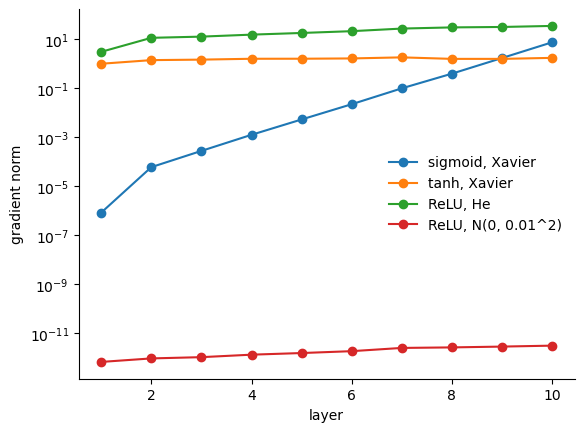

In [7]:
def grad_norms(act, init, depth=10, width=64, seed=0):
    torch.manual_seed(SEED + seed); layers, k, lins = [], Xtr.shape[1], []
    for _ in range(depth):
        l = nn.Linear(k, width); lins.append(l); layers += [l, act()]; k = width
    last = nn.Linear(k, 1); lins.append(last); m = nn.Sequential(*layers, last)
    for l in lins:
        {'xavier': lambda w: nn.init.xavier_normal_(w), 'he': lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
         'small': lambda w: nn.init.normal_(w, 0, 0.01)}[init](l.weight); nn.init.zeros_(l.bias)
    nn.MSELoss()(m(torch.tensor(Xtr[:512])), torch.tensor(ytr[:512]).view(-1, 1)).backward()
    return [float(l.weight.grad.norm()) for l in lins[:-1]]
for nm, a, i in (('sigmoid, Xavier', nn.Sigmoid, 'xavier'), ('tanh, Xavier', nn.Tanh, 'xavier'), ('ReLU, He', nn.ReLU, 'he'),
                 ('ReLU, N(0, 0.01^2)', nn.ReLU, 'small')):
    g = np.mean([grad_norms(a, i, seed=s) for s in range(5)], axis=0)
    print(f'{nm:20s} first layer {g[0]:.2e}   last layer {g[-1]:.2e}')
    plt.semilogy(range(1, 11), g, 'o-', label=nm)
plt.xlabel('layer'); plt.ylabel('gradient norm'); plt.legend(); plt.show()

## §4 The learning rate and the batch size

In [8]:
for lr in (1e-4, 1e-3, 1e-2, 1e-1, 3e-1):
    v = [run_reg('sgd', lr, seed=s, epochs=30)[0][-1] for s in range(3)]
    print(f'SGD lr={lr:g}: validation MSE of 3 seeds', np.round(v, 3))

SGD lr=0.0001: validation MSE of 3 seeds [1.005 1.093 1.142]


SGD lr=0.001: validation MSE of 3 seeds [0.518 0.511 0.518]


SGD lr=0.01: validation MSE of 3 seeds [0.343 0.338 0.335]


SGD lr=0.1: validation MSE of 3 seeds [0.281 0.279 0.281]


SGD lr=0.3: validation MSE of 3 seeds [1.00e+09 1.00e+09 2.83e-01]


§ Experiment yourself: rerun the loop with `bs=16` and `bs=1024` in `run_reg` and compare the validation MSE after 5 epochs.

## §5 Optimisers: SGD, momentum, RMSProp, Adam, AdamW (5 seeds each)

sgd      test MSE 0.314 (sd 0.091)
momentum test MSE 0.288 (sd 0.044)
rmsprop  test MSE 0.302 (sd 0.058)
adam     test MSE 0.272 (sd 0.010)
adamw    test MSE 0.266 (sd 0.006)


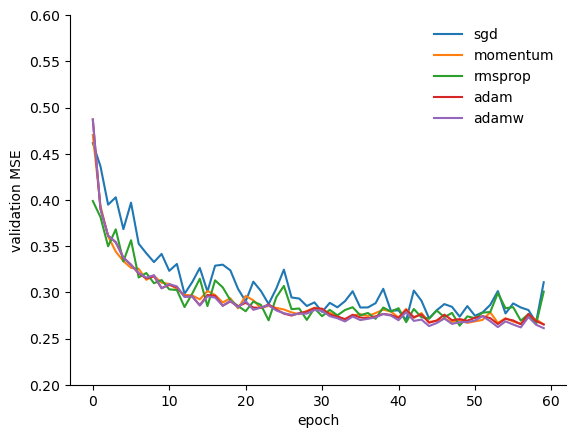

paired t-test SGD vs Adam: TtestResult(statistic=np.float64(1.0061171380847103), pvalue=np.float64(0.37128275162057695), df=np.int64(4))


In [9]:
BEST = {'sgd': 0.1, 'momentum': 0.01, 'rmsprop': 0.003, 'adam': 0.003, 'adamw': 0.003}   # best of three rates on validation (see the slides)
res = {o: [run_reg(o, lr, seed=10 + s) for s in range(5)] for o, lr in BEST.items()}
for o, r in res.items():
    te = np.array([x[1] for x in r]); print(f'{o:8s} test MSE {te.mean():.3f} (sd {te.std(ddof=1):.3f})')
    plt.plot(np.mean([x[0] for x in r], axis=0), label=o)
plt.ylim(0.2, 0.6); plt.xlabel('epoch'); plt.ylabel('validation MSE'); plt.legend(); plt.show()
ts, ta = np.array([x[1] for x in res['sgd']]), np.array([x[1] for x in res['adam']])
print('paired t-test SGD vs Adam:', stats.ttest_rel(ts, ta))

## §6 Learning-rate schedules

In [10]:
for s_ in (None, 'step', 'cosine', 'onecycle'):
    r = [run_reg('momentum', 0.01, seed=20 + s, sched=s_) for s in range(3)]
    print(f'{str(s_):9s} final validation MSE {np.mean([x[0][-1] for x in r]):.3f}   test MSE {np.mean([x[1] for x in r]):.3f}')

None      final validation MSE 0.279   test MSE 0.286


step      final validation MSE 0.270   test MSE 0.270


cosine    final validation MSE 0.266   test MSE 0.265


onecycle  final validation MSE 0.266   test MSE 0.267


## §7 Card fraud: SGD against Adam on a time-ordered split

In [11]:
fr = pd.read_csv(DATA + 'creditcard_fraud_sample.csv').sort_values('Time').reset_index(drop=True)
Xf = np.c_[fr[[f'V{i}' for i in range(1, 29)]].values, np.log1p(fr['Amount'].values)].astype(np.float32)
yf, wf = fr['Class'].values.astype(np.float32), fr['weight'].values
c1, c2 = np.quantile(fr['Time'], [0.6, 0.8]); tr = (fr['Time'] <= c1).values; va = ((fr['Time'] > c1) & (fr['Time'] <= c2)).values
Xf = (Xf - Xf[tr].mean(0)) / Xf[tr].std(0)
def fraud_run(opt_name, lr, seed, epochs=30, bs=256):
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed); m = make_mlp(Xf.shape[1]); opt = make_opt(opt_name, m.parameters(), lr)
    Xt, yt, Xv = torch.tensor(Xf[tr]), torch.tensor(yf[tr]).view(-1, 1), torch.tensor(Xf[va]); ap = []
    for ep in range(epochs):
        idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); nn.BCEWithLogitsLoss()(m(Xt[b]), yt[b]).backward(); opt.step()
        with torch.no_grad():
            ap.append(average_precision_score(yf[va], torch.sigmoid(m(Xv)).numpy().ravel(), sample_weight=wf[va]))
    return ap
for o, lr in (('sgd', 0.01), ('momentum', 0.01), ('adam', 1e-3)):
    a = np.array([fraud_run(o, lr, s) for s in range(5)]); print(f'{o:8s} PR-AUC after epoch 1: {a[:, 0].mean():.3f}, epoch 30: {a[:, -1].mean():.3f}')

sgd      PR-AUC after epoch 1: 0.004, epoch 30: 0.655


momentum PR-AUC after epoch 1: 0.488, epoch 30: 0.738


adam     PR-AUC after epoch 1: 0.592, epoch 30: 0.721


## §8 Case study: 99 % VaR of the S&P 500 with a quantile network

In [12]:
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
px = x[x.ticker == 'SP500'].set_index('date')['adjclose'].dropna()
end = (px.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1); px = px.loc[:end]
r = 100 * np.log(px).diff().dropna()
F = pd.DataFrame({'r': r, 'ar': r.abs(), 's5': r.rolling(5).std(), 's22': r.rolling(22).std(), 's66': r.rolling(66).std(), 'm5': r.rolling(5).mean()})
dfv = pd.concat([F, r.shift(-1).rename('y')], axis=1).dropna(); TAU = 0.01
v_tr = dfv.index <= '2016-12-31'; v_va = (dfv.index > '2016-12-31') & (dfv.index <= '2019-12-31'); v_te = dfv.index > '2019-12-31'
Xv = dfv[F.columns].values.astype(np.float32); Xv = (Xv - Xv[v_tr].mean(0)) / Xv[v_tr].std(0); yv = dfv['y'].values.astype(np.float32)
pin = lambda q, y: torch.mean(torch.maximum(TAU * (y - q), (TAU - 1) * (y - q)))
def var_run(seed, epochs=400):
    torch.manual_seed(SEED + seed); m = make_mlp(Xv.shape[1], (32, 32))
    with torch.no_grad():
        m[-1].bias.fill_(float(np.quantile(yv[v_tr], TAU)))
    opt = torch.optim.Adam(m.parameters(), lr=1e-3); rng = np.random.default_rng(SEED + seed)
    Xt, yt = torch.tensor(Xv[v_tr]), torch.tensor(yv[v_tr]).view(-1, 1); Xa, ya = torch.tensor(Xv[v_va]), torch.tensor(yv[v_va]).view(-1, 1)
    best, state, bad = np.inf, None, 0
    for ep in range(epochs):
        idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), 256):
            b = idx[i:i + 256]; opt.zero_grad(); pin(m(Xt[b]), yt[b]).backward(); opt.step()
        with torch.no_grad():
            vl = float(pin(m(Xa), ya))
        if vl < best - 1e-6:
            best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= 40:
                break
    m.load_state_dict(state)
    with torch.no_grad():
        return m(torch.tensor(Xv)).numpy().ravel()
q = np.mean([var_run(s) for s in range(5)], axis=0)
hs = r.rolling(250).quantile(TAU).reindex(dfv.index).values; yy = dfv['y'].values
def kupiec(viol, p=TAU):
    n, k = len(viol), int(viol.sum()); ph = k / n
    lr = -2 * ((n - k) * np.log(1 - p) + k * np.log(p) - (n - k) * np.log(1 - ph) - k * np.log(ph))
    return k, round(lr, 2), round(stats.chi2.sf(lr, 1), 3)
print('test days', v_te.sum(), ' expected violations', round(TAU * v_te.sum(), 1))
print('quantile MLP (violations, LR, p):', kupiec(yy[v_te] < q[v_te]))
print('historical simulation (violations, LR, p):', kupiec(yy[v_te] < hs[v_te]))

test days 1716  expected violations 17.2
quantile MLP (violations, LR, p): (18, np.float64(0.04), np.float64(0.84))
historical simulation (violations, LR, p): (31, np.float64(9.1), np.float64(0.003))


## §9 CPU or GPU?

In [13]:
import time
dev = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
def timing(d, steps=20):
    m = make_mlp(Xtr.shape[1], (2048, 2048)).to(d); opt = torch.optim.Adam(m.parameters(), 1e-3)
    x, y = torch.tensor(Xtr[:2048], device=d), torch.tensor(ytr[:2048], device=d).view(-1, 1)
    for _ in range(3):
        opt.zero_grad(); nn.MSELoss()(m(x), y).backward(); opt.step()
    t0 = time.time()
    for _ in range(steps):
        opt.zero_grad(); nn.MSELoss()(m(x), y).backward(); opt.step()
    float(m(x).sum())                              # waits for the device to finish
    return (time.time() - t0) / steps * 1000
print('CPU ms per step:', round(timing('cpu'), 1))
if dev != 'cpu':
    print(dev, 'ms per step:', round(timing(dev), 1))

CPU ms per step: 131.6


mps ms per step: 43.6
